# Autodiff: gradients of a simulation against finite differences and Sedov scaling

LUNA's step is written in JAX, so a whole run can be differentiated. Here the output of a 3D
Sedov blast (the registered `Sedov-Blast-3D`, 32³, 200 fixed steps to t = 0.08, MC limiter, FP64)
is differentiated with respect to two initial-condition parameters, the blast energy E and the
ambient density rho0, with forward-mode AD (`jax.jacfwd`). Observables: a kinetic-energy-weighted
shock radius R, the total kinetic energy, and the post-shock pressure. The gradients are compared
with central finite differences (h = 1e-3 in ln E, ln rho0) and with the Sedov-Taylor scaling
R ~ (E/rho0)^(1/5) t^(2/5), P_s ~ E^(2/5) rho0^(3/5), KE ~ E.

The run goes through `luna.launch(cfg, task)` with `autodiff_mode=True`: `main.run` builds the mesh,
the initial state and the production physics, then hands them to `task(init, cfg, physics,
is_main)` instead of the time loop. The task uses `luna.autodiff.rollout.build_simulate`, the
production step scanned over a fixed number of steps. This is the setup of
`tests/test_sedov_gradients.py` (slow tier).

Runtime: about 35 seconds on four CPU cores (an A100 node's CPU cores via SLURM, JAX on the CPU), including JAX start-up and compilation, which dominate.

In [1]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")   # this notebook is sized for a CPU; unset it to use a GPU

import contextlib, io, time
from dataclasses import replace
import numpy as np
import matplotlib.pyplot as plt
from luna import Config, launch


def run(cfg):
    """launch(cfg), as `python main.py` runs it, with its log kept out of the notebook; (RunResult, wall s)."""
    t0 = time.time()
    with contextlib.redirect_stdout(io.StringIO()):
        res = launch(cfg)
    return res, time.time() - t0


# FP64, PLM, HLLC, quiet: the settings of LUNA's accuracy tests
QUIET = dict(enable_x64=True, ORDER=1, LIMITER=0, riemann_solver="hllc", PLOT_AFTER_SIM=False,
             output_cadence=10**6, diag_interval=10**6, enable_checkpointing=False, clear_output_dir=True)
BASE = replace(Config(), **QUIET)

In [2]:
import jax
import jax.numpy as jnp
from luna.autodiff.rollout import build_simulate
from luna.ic_generation import sedov3d

N, N_STEPS, T_END, GAM = 32, 200, 0.08, 5.0 / 3.0
x = (np.arange(N) + 0.5) / N - 0.5
X, Y, Z = np.meshgrid(x, x, x, indexing="ij")          # numpy float64 (JAX starts in FP64 at launch)


def observables(U):
    """(R, KE, P_s): KE-weighted rms radius, total kinetic energy, KE-weighted smooth max of p."""
    ke = 0.5 * (U[1] ** 2 + U[2] ** 2 + U[3] ** 2) / U[0]
    R = jnp.sqrt(jnp.sum(ke * (X * X + Y * Y + Z * Z)) / jnp.sum(ke))
    p = (GAM - 1.0) * (U[4] - ke)
    w = ke ** 8
    return jnp.stack([R, jnp.sum(ke) / N ** 3, jnp.sum(p * w) / jnp.sum(w)])


def task(init, cfg, physics, is_main):
    """d ln(observables) / d ln(E, rho0) by forward-mode AD and by central differences."""
    simulate, _, _, _, theta = build_simulate(init, cfg, physics, is_main)

    def U0(p):                       # point blast: E in the 8 central cells, p_bg = 1e-4 rho0
        prob = sedov3d.Params(E=p[0], rho_bg=p[1], p_bg=1e-4 * p[1], r_blast=1.24)
        return jax.lax.with_sharding_constraint(sedov3d.sedov_blast_3d(replace(cfg, problem=prob)),
                                                init.U.sharding)

    log_obs = jax.jit(lambda lp: jnp.log(observables(simulate(theta, U0(jnp.exp(lp))))))
    lp0 = jnp.log(jnp.array([0.5, 1.0]))
    t0 = time.time()
    J_ad = np.asarray(jax.jacfwd(log_obs)(lp0))
    t_ad = time.time() - t0
    h, J_fd = 1e-3, np.zeros_like(J_ad)
    for j in range(2):
        e = np.zeros(2); e[j] = h
        J_fd[:, j] = (np.asarray(log_obs(lp0 + e)) - np.asarray(log_obs(lp0 - e))) / (2 * h)
    return {"J_ad": J_ad, "J_fd": J_fd, "obs": np.exp(np.asarray(log_obs(lp0))), "t_ad": t_ad}


cfg = replace(BASE, test_problem="Sedov-Blast-3D", SPATIAL_DIMENSION=3, Nx=N, Ny=N, Nz=N,
              BOUNDARY=0, gamma=GAM, LIMITER=1, autodiff_mode=True, autodiff_n_steps=N_STEPS,
              autodiff_fixed_dt=T_END / N_STEPS, write_snapshots=False, enable_diagnostics=False,
              output_dir="snapshots/nb11/run")
t0 = time.time()
with contextlib.redirect_stdout(io.StringIO()):
    res = launch(cfg, task=task)
out = res.extra
print(f"{time.time() - t0:.0f} s in all; the forward-mode Jacobian (2 tangents) took {out['t_ad']:.0f} s")

27 s in all; the forward-mode Jacobian (2 tangents) took 13 s


observable  d ln / d ln E: AD, FD, Sedov    d ln / d ln rho0: AD, FD, Sedov    |AD - FD|
R           +0.20072 +0.20072 +0.20      -0.20072 -0.20072 -0.20       3.6e-06
KE          +1.01368 +1.01376 +1.00      -0.01368 -0.01376 +0.00       7.8e-05
P_s         +0.49939 +0.49945 +0.40      +0.50061 +0.50055 +0.60       6.4e-05


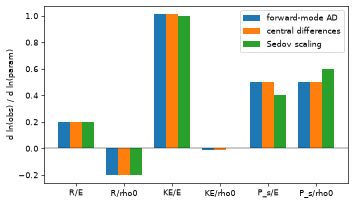

In [3]:
names = ("R", "KE", "P_s")
sedov = np.array([[0.2, -0.2], [1.0, 0.0], [0.4, 0.6]])
print("observable  d ln / d ln E: AD, FD, Sedov    d ln / d ln rho0: AD, FD, Sedov    |AD - FD|")
for i, nm in enumerate(names):
    a, f = out["J_ad"][i], out["J_fd"][i]
    print(f"{nm:5s}       {a[0]:+.5f} {f[0]:+.5f} {sedov[i, 0]:+.2f}      "
          f"{a[1]:+.5f} {f[1]:+.5f} {sedov[i, 1]:+.2f}       {np.abs(a - f).max():.1e}")
fig, a = plt.subplots(figsize=(6, 3.5), dpi=60)
pos = np.arange(6)
a.bar(pos - 0.25, out["J_ad"].ravel(), 0.25, label="forward-mode AD")
a.bar(pos, out["J_fd"].ravel(), 0.25, label="central differences")
a.bar(pos + 0.25, sedov.ravel(), 0.25, label="Sedov scaling")
a.set_xticks(pos, [f"{n}/{p}" for n in names for p in ("E", "rho0")])
a.set_ylabel("d ln(obs) / d ln(param)"); a.axhline(0, color="k", lw=0.5); a.legend()
fig.tight_layout()

**What this shows.** Forward-mode AD and central differences agree to 4e-6 (R) and 8e-5 (KE, P_s) in the log-derivatives; dlnR/dlnE = 0.2007 against the Sedov value 1/5, dlnR/dlnrho0 = -0.2007 against -1/5. KE and P_s depart from the Sedov scaling (KE: 1.014 vs 1; P_s: 0.50, 0.50 vs 0.4, 0.6): P_s here is a kinetic-energy-weighted smooth maximum of p, a differentiable stand-in, not the post-shock pressure, and the 32³ blast with a finite ambient pressure is not exactly self-similar. What is checked is the gradient of the run as computed, not its physics.

Status (docs/CLAIMS.md): "Gradients through the solver match finite differences" is *validated*
for the cases tested (`tests/test_autodiff_validation.py:67`, `tests/test_autodiff_sharded.py:165`);
differentiation through whole simulations is *shown*, with known gaps in `docs/AUTODIFF.md`. This
Sedov case is asserted in `tests/test_sedov_gradients.py` (slow tier), which docs/CLAIMS.md does
not list.